In [2]:
# Cell 1: import library
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt 
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
# Cell 2: load dataset
df = pd.read_csv("../data/raw/bitext_raw.csv")
df.head()

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


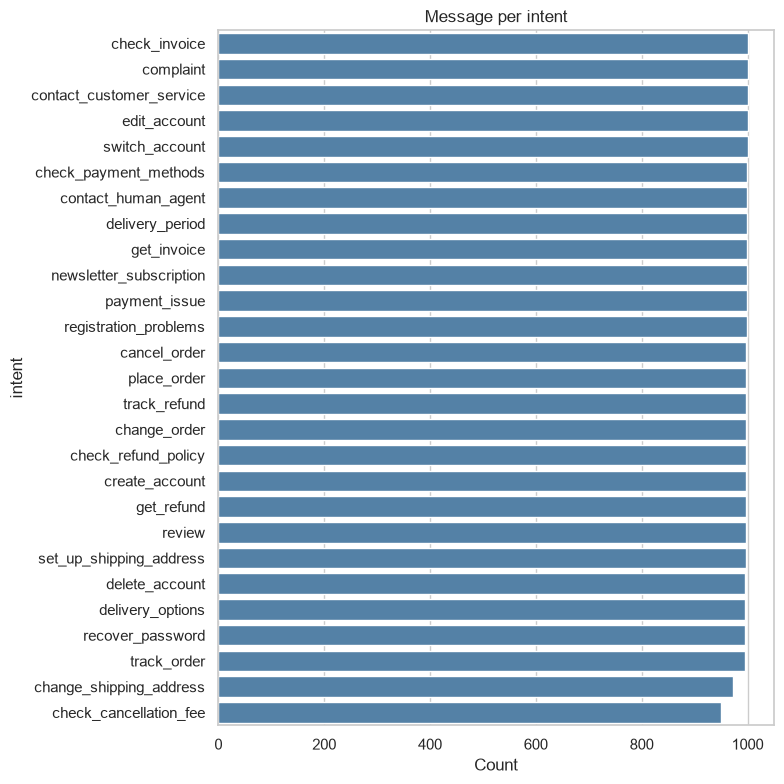

Larges / smallest class ratio: 1.05


In [4]:
# Cell 3: intent distribution
counts = df["intent"].value_counts()
plt.figure(figsize=(8, 8))
sns.barplot(x=counts.values, y = counts.index, color="steelblue")
plt.title("Message per intent")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

print("Larges / smallest class ratio:", round(counts.max() / counts.min(), 2))

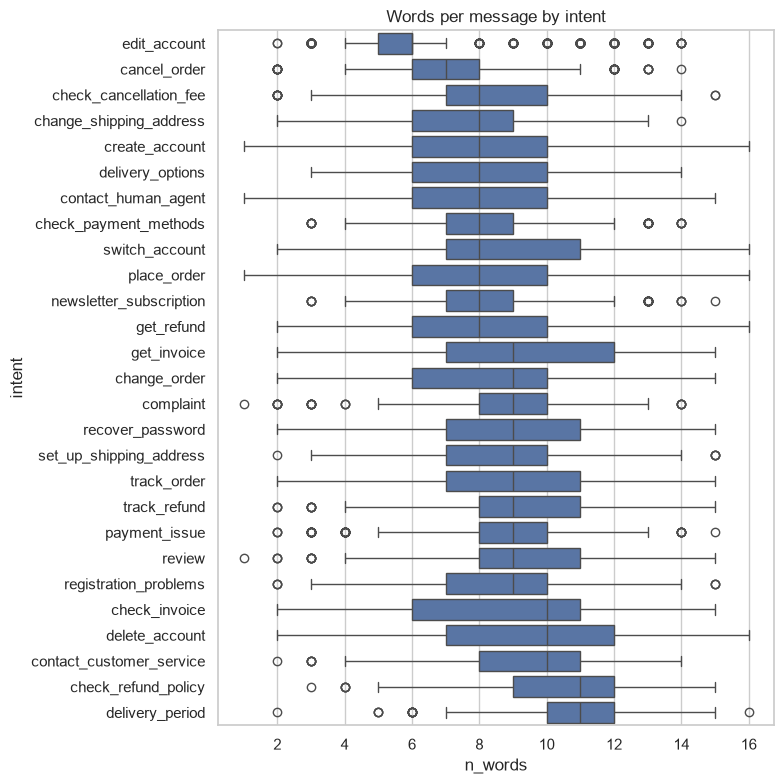

In [5]:
# Cell 4: message length per intent
df["n_words"] = df["instruction"].str.split().str.len()
df["n_chars"] = df["instruction"].str.len()

order = df.groupby("intent")["n_words"].median().sort_values().index
plt.figure(figsize=(8, 8))
sns.boxplot(data=df, x="n_words", y="intent", order=order)
plt.title("Words per message by intent")
plt.tight_layout()
plt.show()

In [6]:
# Cell 5: the shortest and longest messages
print("Shortest:")
display(df.nsmallest(10, "n_words")[["instruction", "intent"]])
print("Longest:")
display(df.nlargest(5, "n_words")[["instruction", "intent"]])

Shortest:


,instruction,intent
7449,complaint,complaint
9025,contactingassistant,contact_human_agent
10231,register,create_account
19665,makepurchase,place_order
22443,review,review
83,cancelling order,cancel_order
311,canceling order,cancel_order
370,cancel purchase732201349959,cancel_order
711,order cancelation,cancel_order
729,cancel purchase370795561790,cancel_order


Longest:


,instruction,intent
9942,I do not know what to do to create a {{Account...,create_account
9951,I want to open a {{Account Type}} account for ...,create_account
10969,I do not know what I have to do to remove a da...,delete_account
13603,i have to see how soon can i expect my item oh...,delivery_period
16526,i have paid {{Currency Symbol}}{{Refund Amount...,get_refund


In [7]:
# Cell 6: flag letters, counted one by one
flag_counts = (df["flags"].str.split("").explode()
               .replace("", np.nan).dropna().value_counts())
print(flag_counts)

flags
B    26872
L    24115
Q     8968
I     7839
Z     5286
M     4920
C     2646
K     2227
E     1882
P     1329
W     1288
N      463
S      417
V       77
Name: count, dtype: int64


In [8]:
# Cell 7: do typos (flag Z) change message length?
df["has_Z"] = df["flags"].str.contains("Z")
print(df.groupby("has_Z")["n_words"].agg(["count", "mean"]))

       count      mean
has_Z                 
False  21586  8.768507
True    5286  8.374385


In [9]:
# Cell 8: one-word messages and glued digits
one_word = df[df["n_words"] == 1]
print("One-word messages:", len(one_word))
display(one_word["instruction"].value_counts().head(15))

has_digits = df["instruction"].str.contains(r"\d", regex=True)
print("Messages with digits:", has_digits.sum())
display(df[has_digits][["instruction", "intent"]].head(10))

One-word messages: 5


instruction
complaint              1
contactingassistant    1
register               1
makepurchase           1
review                 1
Name: count, dtype: int64

Messages with digits: 1089


,instruction,intent
370,cancel purchase732201349959,cancel_order
374,I need help to cancel purchase370795561790,cancel_order
729,cancel purchase370795561790,cancel_order
763,cancel purchase00123842,cancel_order
779,cancel purchase113542617735902,cancel_order
910,cancel purchase00004587345,cancel_order
1067,i cant add some items to order370795561790,change_order
1076,update purchase00004587345,change_order
1080,need to change several products of purchase113...,change_order
1180,need to edit order113542617735902 how to do it,change_order


In [ ]:
# Cell 9: how common is each flag inside each intent (top 5 flags)
top_flags = ["L", "Q", "I", "Z", "M"]
for f in top_flags:
    df[f"flag_{f}"] = df["flags"].str.contains(f)

share = df.groupby("intent")[[f"flag_{f}" for f in top_flags]].mean().round(2)
display(share.head(10))

,flag_L,flag_Q,flag_I,flag_Z,flag_M
intent,,,,,
cancel_order,0.66,0.32,0.18,0.20,0.06
change_order,0.87,0.32,0.27,0.19,0.26
change_shipping_address,0.97,0.28,0.22,0.20,0.15
check_cancellation_fee,0.97,0.30,0.38,0.19,0.48
check_invoice,0.84,0.34,0.27,0.19,0.24
check_payment_methods,0.98,0.35,0.35,0.20,0.00
check_refund_policy,0.91,0.36,0.22,0.20,0.00
complaint,0.98,0.35,0.30,0.20,0.00
contact_customer_service,0.96,0.32,0.41,0.20,0.00


In [11]:
# Cell 10: vocabulary size
tokens = df["instruction"].str.lower().str.findall(r"[a-z']+").explode()
print("Total tokens:", len(tokens))
print("Unique tokens:", tokens.nunique())
print(tokens.value_counts().head(20))

Total tokens: 233116
Unique tokens: 2849
instruction
i             18875
to            16400
the            6413
help           6319
a              6086
account        5400
do             5348
can            5274
order          4847
my             4774
how            4207
need           4059
of             3995
me             3661
what           3136
want           3110
assistance     3005
have           2957
number         2953
know           2691
Name: count, dtype: int64


# Conclusion

## 1. What we did in this notebook
1. Set up the project with a cookiecutter structure, a `customer-support` conda environment, Git and **DVC** (local remote storage).
2. Loaded the Bitext customer support dataset from `data/raw/bitext_raw.csv`. It was downloaded as `Bitext_Sample_Customer_Support.csv` and renamed. The raw file is tracked with DVC (a small `.dvc` pointer file goes into Git, the data goes into the DVC remote), so every result can be tied to an exact data version.
3. Inspected its dimensions, columns, data types, memory usage, missing values and duplicates.
4. Identified the target labels and how they relate to each other.
5. Looked at the `flags` column, sample messages, message length and template placeholders.
6. Left the raw file untouched. All cleaning happens in notebook 03 and is saved to `data/processed/`.

## 2. Dataset summary

| Property | Value |
|---|---|
| Rows | 26,872 |
| Columns | 5 (`flags`, `instruction`, `category`, `intent`, `response`) |
| Memory usage | about 20 MB |
| Missing values | 0 in every column |
| Exact duplicate rows | 0 |
| Duplicate customer messages | 2,237 extra copies (989 unique texts repeated, 3,226 rows involved, about 8%) |
| Categories / intents | 11 / 27 |
| Messages per intent | about 950 to 1,000 |

The file is named "Sample", but it has the full size (26,872 rows) and all 27 intents.

## 3. What each column means

| Column | Meaning | Role in this project |
|---|---|---|
| `instruction` | The customer message | **Model input** |
| `intent` | Fine-grained label (27 classes) | **Target** for intent classification |
| `category` | Parent group of the intent (11 classes) | Useful for routing and department analysis |
| `flags` | Letters describing how the sentence was generated (for example typos, questions, colloquial style) | **Not** a model feature, because real tickets have no flags. Used for sliced error analysis |
| `response` | Agent reply to the message | Not used for intent classification. May help with the recommended-action feature later |

Note: the meaning of individual flag letters (for example `Z` for noise/typos) was inferred from sample messages and should be checked against the official Bitext documentation before it is quoted in the README.

## 4. Key findings

**Labels**
- `intent` is the target with 27 classes, grouped into 11 `category` values.
- Classes are almost perfectly balanced (about 950 to 1,000 each). The largest to smallest ratio is only about 1.05, so resampling and class weights are not needed.
- Naming trap: `CANCEL` is a category that contains only `check_cancellation_fee`, while `cancel_order` belongs to `ORDER`. These are likely to be confused and will be examined in error analysis.

**Data quality**
- There are no missing values and no exact duplicate rows.
- About 8% of the messages are repeated copies of the same text. No duplicated text carries more than one intent, so removing duplicates does not lose label information.

**Message length**
- Mean 8.7 words, median 9, standard deviation 2.6, minimum 1, maximum 16.
- Messages are short, single-sentence requests. Real support tickets are usually longer, noisier and often contain more than one problem.

**Placeholders**
- 24.8% of messages contain template tokens such as `{{Order Number}}` (the most common), `{{Account Type}}`, `{{Person Name}}`, `{{Account Category}}`, `{{Refund Amount}}`, `{{Currency Symbol}}`, `{{Delivery City}}`, `{{Delivery Country}}` and `{{Invoice Number}}`.
- Risk: the model may learn these tokens as a shortcut to the intent (for example `{{Refund Amount}}` points to a refund intent) instead of learning the meaning of the sentence.
- Opportunity: the placeholders mark where entities sit, which can be used to build synthetic NER training data in notebook 09.

**Flags**
- Flags describe how a sentence was generated, not what the customer wrote. They are useful for slicing errors (for example, does accuracy drop on messages with typos?) but must never be used as features.

## 5. Limitations of this dataset
1. **Synthetic and template-generated.** Many sentences are paraphrases of the same template, so the data is much cleaner than real tickets.
2. **Unrealistically balanced classes.** Real support data is imbalanced.
3. **Short messages.** No multi-sentence, emotional or multi-issue tickets.
4. **Placeholders instead of real values.** Real tickets contain actual order IDs, amounts, names and dates.
5. **Near-duplicates.** Even after exact duplicates are removed, many messages differ only by a typo or a synonym. A random train/test split would leak these across sets and inflate the test score.
6. **No labels for priority, department or duplicate pairs.** The dataset only supports intent classification directly. The other tasks need separate labels, rules or additional data, and these will be documented honestly.

## 6. Decisions carried into the next notebooks
1. Deduplicate on the (normalized) message text **before** splitting the data.
2. Use a **grouped** train/validation/test split, so that near-duplicate messages stay on the same side, and keep a test set that is never touched during development.
3. Keep `flags` only for error analysis.
4. Keep the `{{...}}` placeholders in the raw data, and compare models trained with and without masked placeholders (notebook 05).
5. Report macro F1 together with accuracy. Expect very high scores from simple models on this data, so a high score alone is not strong evidence.
6. Build a small **hand-written test set of realistic messages** (longer, noisy, multi-sentence, with typos and real-looking IDs) to measure how well the models transfer beyond Bitext.
7. Create priority labels, duplicate pairs and the intent-to-department mapping separately, and document how each label was obtained.

## 7. Interview takeaways
- Why is the raw data kept read-only and tracked with DVC? Because results must be reproducible, and any change to the data creates a new, identifiable version.
- Why is a perfectly balanced dataset a warning sign? It is a sign of synthetic data, and real data will be imbalanced.
- Why do duplicates across train and test matter? The model is tested on text it has already seen, so the score measures memorization and not generalization.
- Why is `flags` excluded from the features? It describes how the text was generated, and it won't exist when a real customer writes a ticket.
- Why is high accuracy on Bitext not enough? The data is clean, short and template-based, so a good score may not carry over to real tickets.

**Next notebook:** `02_eda.ipynb`